# ETH and exponential-time algorithms: in depth, in Python and on an FPGA

*Русская версия: [`eth_alg_learn.ipynb`](eth_alg_learn.ipynb).*

This notebook explains why problems such as 3-SAT and Subset Sum need exponential time, what exactly the
**Exponential Time Hypothesis (ETH)** states, how algorithms reduce the **base** of the exponent, and what an
**FPGA** can and cannot do about an exponent.

Every claim is checked three ways: **mathematical derivation → Python experiment → Verilog model simulated in
Icarus Verilog**.

| Section | Topic |
|---|---|
| 1 | The exponential wall: why an S-fold speedup only adds log S to the problem size |
| 2 | 3-SAT, ETH, SETH, the Sparsification Lemma, the phase transition |
| 3 | Branching and recurrences: where 1.839ⁿ and 1.466ⁿ come from |
| 4 | Brute force → backtracking → clause branching → DPLL: measuring the base |
| 5 | Schöning's algorithm: deriving (4/3)ⁿ and testing it |
| 6 | Subset Sum: brute force, Gray code, meet-in-the-middle (2ⁿ → 1.414ⁿ) |
| 7 | FPGA: parallel 3-SAT brute force (`sat_brute.v`) |
| 8 | FPGA: Gray-code Subset Sum engine (`ss_engine.v`), multiplexer vs LUTRAM |
| 9 | FPGA done right: DPLL on the ARM + single-cycle BCP in the PL (`bcp_unit.v`) |
| 10 | The big picture and the ETH limit |
| 11 | Exercises |

Target hardware: **Zynq-7010 (XC7Z010), 7Z-Lite board, 50 MHz crystal**:
17,600 LUT6, 35,200 FF, 2.1 Mbit BRAM.

In [1]:
import sys, os, math, time, random
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
import pycosat

from ethlearn import sat, recurrence as rc, subset_sum as ss, fpga

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .3})
FIG = '../figures/en'
os.makedirs(FIG, exist_ok=True)
T_ = lambda s: fpga.fmt_time(s, 'en')
print('iverilog available:', fpga.have_iverilog())

iverilog available: True


## 1. The exponential wall

### 1.1 Every exponential is a power of two
$$c^n = 2^{n\log_2 c}.$$
An algorithm running in $c^n$ behaves like an exhaustive search over **$n\log_2 c$ binary variables**.
For example, $1.307^n = 2^{0.386n}$: the best known 3-SAT algorithm effectively "enumerates" about 39% of the
variables. Lowering the base means lowering the fraction of variables that really have to be enumerated.

### 1.2 The constant-speedup theorem
Suppose that in time $t$, on a machine doing $r$ operations per second, a $c^n$ algorithm solves instances
up to size $n_0$: $c^{n_0} = rt$. Make the machine $S$ times faster:
$$c^{n_1} = S\,r\,t = S\,c^{n_0}\;\Rightarrow\; n_1 = n_0 + \log_c S.$$

**Conclusion:** an $S$-fold speedup (FPGA, cluster, next CPU generation) **adds** $\log_c S$ to the
feasible size, it does not multiply it. For $c=2$:
- ×1000 → +10 variables;
- ×10⁶ → +20 variables.

An **algorithm** with a smaller base $c' < c$ **multiplies** the feasible size instead:
$$c'^{n_1} = c^{n_0} \Rightarrow n_1 = n_0\,\frac{\ln c}{\ln c'}.$$
Going from $2^n$ to $1.414^n$ (meet-in-the-middle) doubles $n$; going from $2^n$ to $1.307^n$ multiplies it by 2.59.

In [2]:
rate = 1e9  # operations per second
print(f"{'n':>4} | {'2^n':>10} | {'time at 1e9/s':>26} | {'1.307^n (PPSZ)':>22}")
for n in [20, 30, 40, 50, 60, 80, 100]:
    print(f"{n:>4} | {2.0**n:>10.2e} | {T_(2.0**n/rate):>26} | {T_(1.307**n/rate):>22}")

   n |        2^n |              time at 1e9/s |         1.307^n (PPSZ)
  20 |   1.05e+06 |                     1.0 ms |               211.6 ns
  30 |   1.07e+09 |                      1.1 s |                 3.1 µs
  40 |   1.10e+12 |                   18.3 min |                44.8 µs
  50 |   1.13e+15 |                  13.0 days |               651.3 µs
  60 |   1.15e+18 |                 36.5 years |                 9.5 ms
  80 |   1.21e+24 |             3.83e+07 years |                  2.0 s
 100 |   1.27e+30 | 2.91e+03 × age of the Universe |                7.1 min


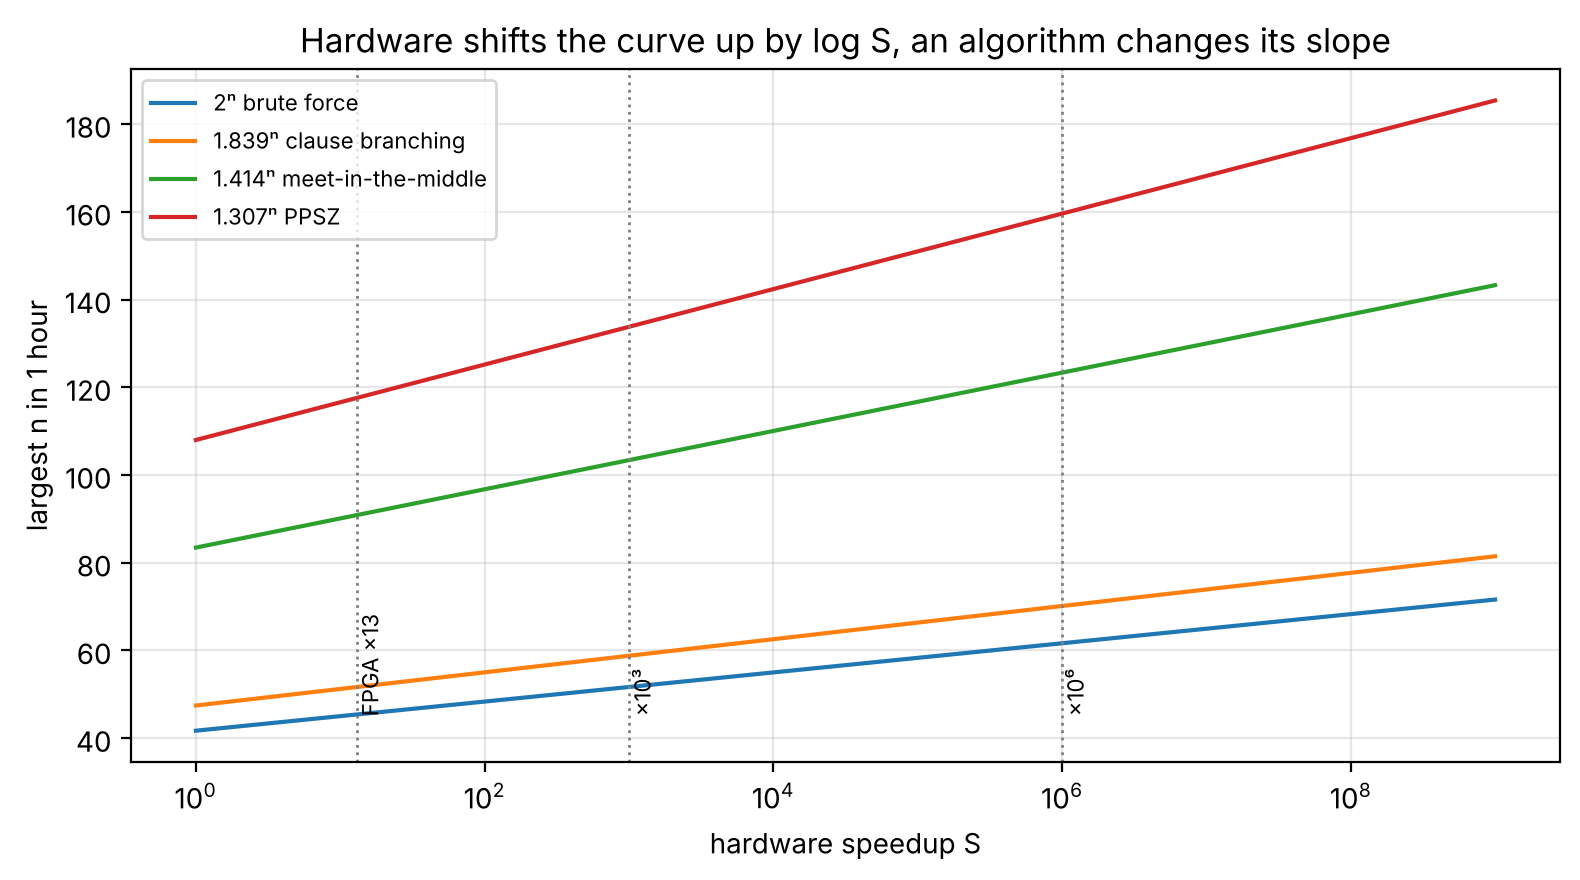

S =        13: +3.7 variables at 2ⁿ, +9.6 at 1.307ⁿ
S =      1000: +10.0 variables at 2ⁿ, +25.8 at 1.307ⁿ
S =   1000000: +19.9 variables at 2ⁿ, +51.6 at 1.307ⁿ


In [3]:
# Largest n solvable in 1 hour for different speedups S and bases c
S = np.logspace(0, 9, 200)
budget = 3600 * 1e9            # 1 hour at 1e9 ops/s
fig, ax = plt.subplots()
for c, name in [(2, '2ⁿ brute force'), (1.839, '1.839ⁿ clause branching'),
                (1.414, '1.414ⁿ meet-in-the-middle'), (1.307, '1.307ⁿ PPSZ')]:
    ax.semilogx(S, np.log(budget * S) / np.log(c), label=name)
for s, lab in [(13, 'FPGA ×13'), (1e3, '×10³'), (1e6, '×10⁶')]:
    ax.axvline(s, color='gray', ls=':', lw=1); ax.text(s, 45, lab, rotation=90, va='bottom', fontsize=8)
ax.set_xlabel('hardware speedup S'); ax.set_ylabel('largest n in 1 hour')
ax.set_title('Hardware shifts the curve up by log S, an algorithm changes its slope'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{FIG}/01_wall.png', dpi=110); plt.show()

for S_ in [13, 1e3, 1e6]:
    print(f"S = {S_:>9.0f}: +{fpga.extra_vars(S_, 2):.1f} variables at 2ⁿ, "
          f"+{fpga.extra_vars(S_, 1.307):.1f} at 1.307ⁿ")

## 2. 3-SAT and the Exponential Time Hypothesis

### 2.1 The problem
A 3-CNF formula is a conjunction of $m$ clauses, each a disjunction of three literals ($x_i$ or $\neg x_i$).
Question: is there an assignment $x\in\{0,1\}^n$ satisfying every clause?

- 3-SAT is NP-complete (Cook–Levin 1971, Karp 1972);
- 2-SAT is solvable in $O(n+m)$: the clause $(a\lor b)$ is equivalent to the implications $\neg a\to b$, $\neg b\to a$,
  and the formula is unsatisfiable iff some $x$ and $\neg x$ lie in the same strongly connected component.
  Between 2 and 3 there is a jump from linear to exponential time.

### 2.2 Statements
**ETH (Impagliazzo–Paturi, 1999).** There is $\delta>0$ such that 3-SAT cannot be solved in $O(2^{\delta n})$.
Equivalently $s_3 > 0$, where
$$s_k = \inf\{\delta : k\text{-SAT is solvable in } O(2^{\delta n})\}.$$
It is known that $s_3 \le s_4 \le \dots \le 1$; the best known algorithms give $s_3 \le \log_2 1.307 \approx 0.386$.

**SETH.** $\lim_{k\to\infty} s_k = 1$: for every $\varepsilon>0$ there is a $k$ such that $k$-SAT
cannot be solved in $O(2^{(1-\varepsilon)n})$. In other words, for wide clauses brute force is almost optimal.

### 2.3 The Sparsification Lemma
For every $\varepsilon>0$ a $k$-CNF formula can be turned, in time $2^{\varepsilon n}\cdot\mathrm{poly}(n)$, into
a disjunction of $t\le 2^{\varepsilon n}$ formulas, each with $m = O(n)$ clauses,
such that the original is satisfiable iff at least one of them is.

Hence ETH is equivalent to "3-SAT cannot be solved in $2^{o(m)}$", i.e. in terms of the number of **clauses**.
This matters because standard reductions blow up the size in proportion to $m$, not $n$.

### 2.4 How ETH yields lower bounds for other problems
If a reduction maps 3-SAT with $m$ clauses to a problem of size $N = O(m)$ (a linear reduction),
then a $2^{o(N)}$ algorithm for that problem would give $2^{o(m)}$ for 3-SAT, contradicting ETH. This gives:

| Problem | Lower bound under ETH | Why |
|---|---|---|
| 3-coloring a graph on $N$ vertices | $2^{\Omega(N)}$ | $O(1)$-vertex gadget per clause |
| Vertex Cover, Independent Set, Clique | $2^{\Omega(N)}$ | linear reduction |
| Hamiltonian cycle | $2^{\Omega(N)}$ | linear reduction |
| $k$-Clique | no $f(k)\,N^{o(k)}$ | reduction by Chen et al. |
| Problems on planar graphs | $2^{\Omega(\sqrt N)}$ | crossing gadgets give $N = O(m^2)$ |
| Subset Sum with $n$ numbers | $2^{\Omega(n)}$, with $n\log$-bit numbers | linear in $n$ |

### 2.5 The phase transition
For random formulas with $m=\alpha n$ the probability of satisfiability drops sharply around $\alpha\approx4.27$.
That is exactly where formulas are hardest: for small $\alpha$ a solution is easy to find, for large $\alpha$
unsatisfiability is easy to prove. Let us check this experimentally.

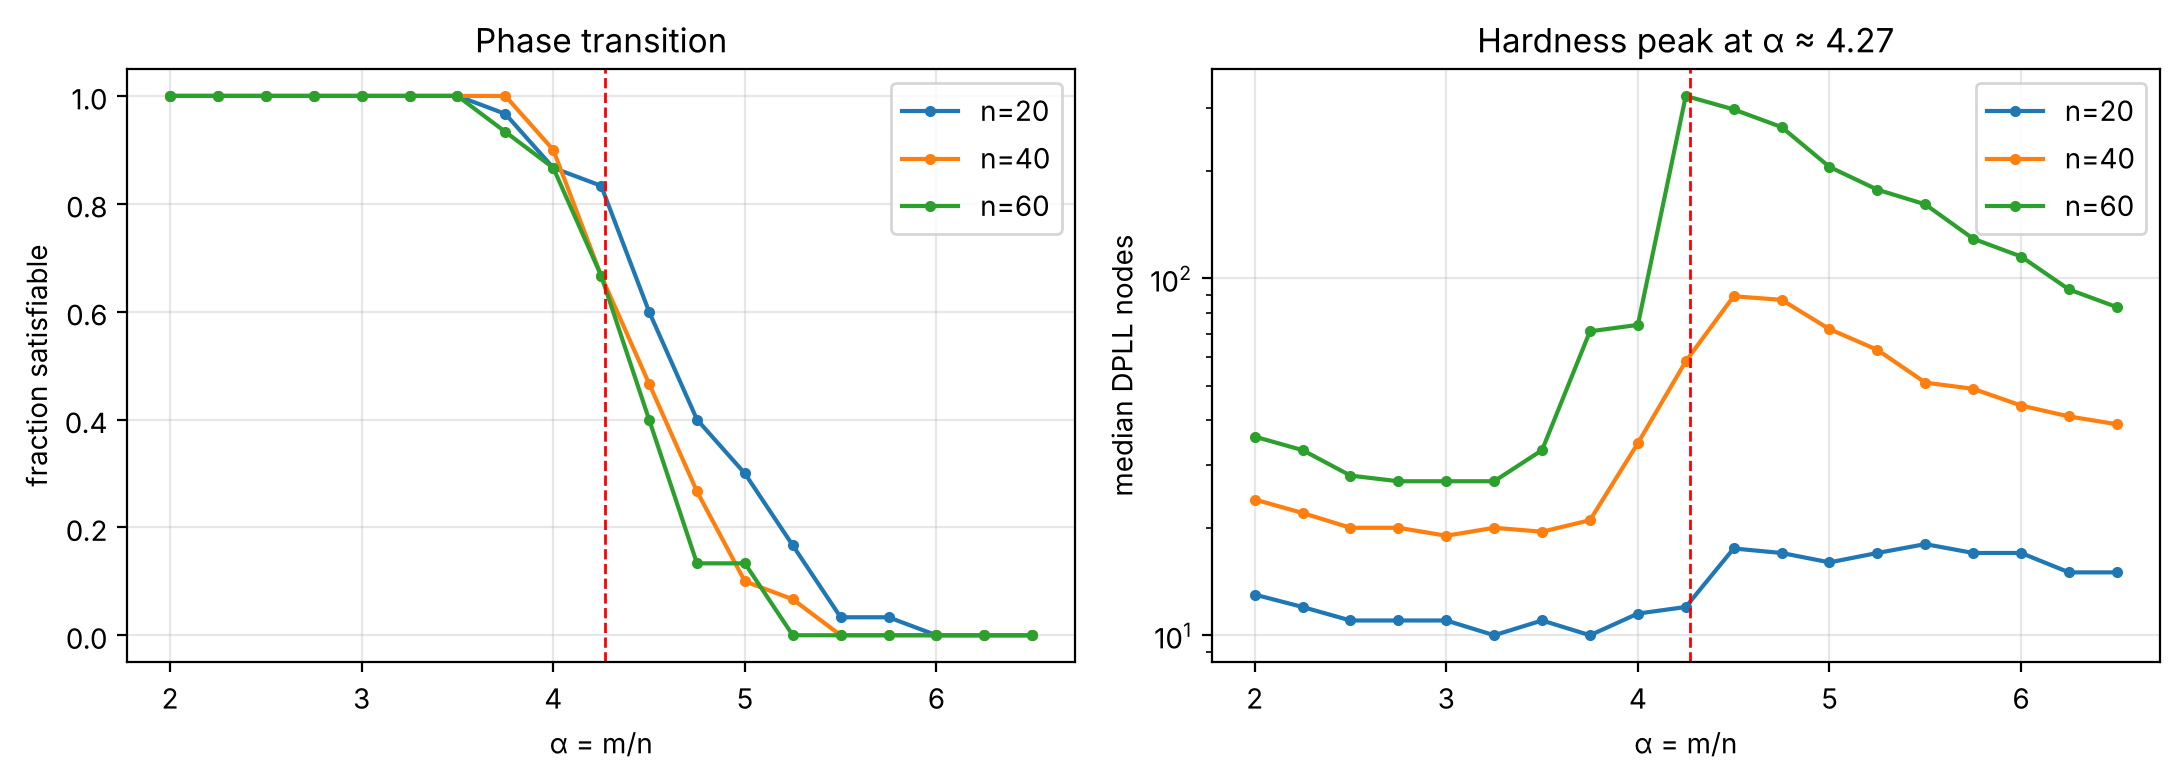

In [4]:
alphas = np.arange(2.0, 6.51, 0.25)
res = {}
for n in [20, 40, 60]:
    p_sat, nodes = [], []
    for a_ in alphas:
        s_cnt, nd = 0, []
        for seed in range(30 if n < 60 else 15):
            cnf = sat.random_3sat_ratio(n, a_, seed=10_000 * n + seed)
            x, st = sat.dpll(cnf, n)
            s_cnt += x is not None
            nd.append(st['nodes'])
        p_sat.append(s_cnt / (30 if n < 60 else 15)); nodes.append(np.median(nd))
    res[n] = (p_sat, nodes)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for n, (p, nd) in res.items():
    a1.plot(alphas, p, 'o-', ms=3, label=f'n={n}')
    a2.semilogy(alphas, nd, 'o-', ms=3, label=f'n={n}')
for a in (a1, a2): a.axvline(4.27, color='r', ls='--', lw=1); a.set_xlabel('α = m/n'); a.legend()
a1.set_ylabel('fraction satisfiable'); a1.set_title('Phase transition')
a2.set_ylabel('median DPLL nodes'); a2.set_title('Hardness peak at α ≈ 4.27')
fig.tight_layout(); fig.savefig(f'{FIG}/02_phase.png', dpi=110); plt.show()

**What we see:** as $n$ grows, the transition gets sharper, and the hardness peak sits at $\alpha\approx4.27$.
All further experiments with random formulas use $\alpha=4.27$.

## 3. Branching and recurrences: where the bases come from

### 3.1 The general method
A recursive algorithm on a problem of "size" $n$ (number of free variables) does polynomial work and calls itself
on subproblems of sizes $n-d_1,\dots,n-d_r$. The number of leaves of the search tree is
$$T(n) = T(n-d_1)+\dots+T(n-d_r).$$
Try $T(n)=c^n$ and divide by $c^n$:
$$\boxed{\;1 = c^{-d_1}+c^{-d_2}+\dots+c^{-d_r}\;}\qquad(*)$$
For $c>1$ the left-hand side decreases strictly from $r$ to $0$, so there is exactly one root $c>1$.
It is the **branching number** of the branching vector $(d_1,\dots,d_r)$. Multiplying $(*)$ by $c^D$, $D=\max d_i$,
gives the characteristic polynomial of the linear recurrence $c^D-\sum c^{D-d_i}=0$;
$c$ is its largest positive root.

**Rigorously:** by induction $T(n)\le c^n$ provided $T(k)\le c^k$ for $k<n$:
$T(n)\le\sum c^{n-d_i}=c^n\sum c^{-d_i}=c^n$.

### 3.2 Examples
| Algorithm | Branches | Vector $d$ | $c$ |
|---|---|---|---|
| Brute force: $x=0$ or $x=1$ | 2 | (1,1) | 2 |
| 3-SAT, branching on a clause $(l_1\lor l_2\lor l_3)$: $l_1{=}1$ / $l_1{=}0,l_2{=}1$ / $l_1{=}0,l_2{=}0,l_3{=}1$ | 3 | (1,2,3) | 1.839 |
| Same, but the clause already has two literals | 2 | (1,2) | 1.618 (golden ratio) |
| Independent Set, vertex of degree ≥ 2: skip $v$ / take $v$ and drop its neighbours | 2 | (1,3) | 1.466 |
| Vertex Cover of size $k$ on edge $(u,v)$: take $u$ / take $v$ | 2 | (1,1) in $k$ | $2^k$ |
| Vertex Cover, vertex of degree ≥ 3: take $v$ / take all of $N(v)$ | 2 | (1,3) in $k$ | $1.466^k$ |

**Why clause branching is correct:** the three branches are mutually exclusive and together cover every
satisfying assignment of the clause (7 of the 8 combinations of $l_1l_2l_3$; 000 does not satisfy it).
Brute force also spends branches on 000, which is where the gain comes from.

In [5]:
cases = {
    'brute force (1,1)': [1, 1],
    '3-literal clause (1,2,3)': [1, 2, 3],
    '2-literal clause (1,2)': [1, 2],
    'independent set (1,3)': [1, 3],
    'IS, degree 3: (1,4)': [1, 4],
    '4-SAT on a clause (1,2,3,4)': [1, 2, 3, 4],
}
print(f"{'vector':32} {'c (bisection)':>14} {'c (poly roots)':>15} {'log2 c':>8}")
for name, d in cases.items():
    c = rc.branching_number(d)
    roots = rc.char_poly_roots(d)
    cmax = max(r.real for r in roots if abs(r.imag) < 1e-9)
    print(f"{name:32} {c:14.6f} {cmax:15.6f} {rc.log2_base(c):8.3f}")

vector                            c (bisection)  c (poly roots)   log2 c
brute force (1,1)                      2.000000        2.000000    1.000
3-literal clause (1,2,3)               1.839287        1.839287    0.879
2-literal clause (1,2)                 1.618034        1.618034    0.694
independent set (1,3)                  1.465571        1.465571    0.551
IS, degree 3: (1,4)                    1.380278        1.380278    0.465
4-SAT on a clause (1,2,3,4)            1.927562        1.927562    0.947


Note: for $k$-SAT, clause branching gives the vector $(1,2,\dots,k)$, and the root tends to 2 as $k\to\infty$.
This is a simple illustration of SETH: with wide clauses naive branching is barely better than brute force.
Let us also check convergence of the recurrence itself: $T(n+1)/T(n)\to c$.

In [6]:
T = rc.unroll([1, 2, 3], 40)
for n in [5, 10, 20, 30, 40]:
    print(f"n={n:2d}  T(n)={T[n]:>14,}  T(n)/T(n-1)={T[n]/T[n-1]:.6f}")
print('c =', rc.branching_number([1, 2, 3]))

n= 5  T(n)=            31  T(n)/T(n-1)=1.823529
n=10  T(n)=           653  T(n)/T(n-1)=1.839437
n=20  T(n)=       289,329  T(n)/T(n-1)=1.839287
n=30  T(n)=   128,199,521  T(n)/T(n-1)=1.839287
n=40  T(n)=56,804,250,945  T(n)/T(n-1)=1.839287
c = 1.8392867552144407


## 4. From brute force to DPLL: measuring the base experimentally

Four solvers on the same formulas ($\alpha=4.27$):

1. **Brute force** — assignments $0,1,2,\dots$ in increasing order, counting checked assignments. Worst case $2^n$.
2. **Backtracking** — the tree over $x_1,x_2,\dots$, pruning a branch as soon as some clause becomes false.
3. **Clause branching** (Monien–Speckenmeyer) — branch on the shortest unsatisfied clause. Bound $1.839^n$.
4. **DPLL** — unit propagation (a clause with exactly one free literal forces that literal to be true) + branching.

The base is estimated by the regression $\log_2(\text{work}) \approx a + b\,n$, giving $c = 2^b$.
On random formulas the measured bases are **smaller** than the worst case: the recurrence gives an upper bound,
and on random formulas clauses shrink quickly.

experiments took 32 s


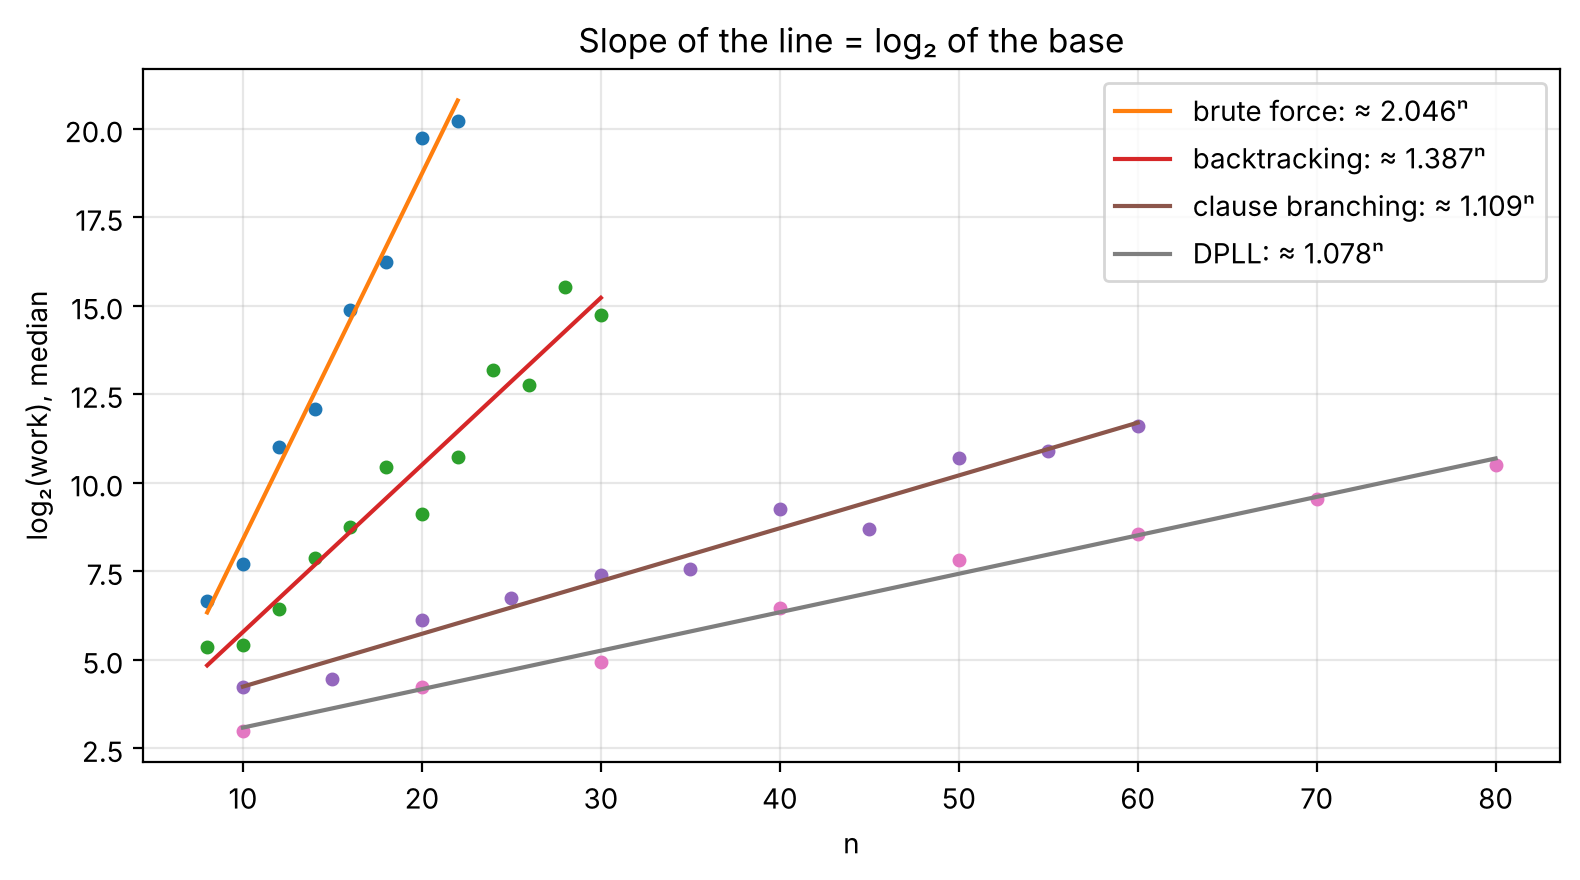

brute force        c ≈ 2.046   (2^1.033 n)
backtracking       c ≈ 1.387   (2^0.472 n)
clause branching   c ≈ 1.109   (2^0.149 n)
DPLL               c ≈ 1.078   (2^0.109 n)


In [7]:
def measure(solver, ns, seeds, key):
    out = []
    for n in ns:
        vals = [solver(sat.random_3sat_ratio(n, 4.27, seed=777 * n + s), n)[1][key] for s in range(seeds)]
        out.append(np.median(vals))
    return np.array(out, float)

t0 = time.time()
ns_bf = np.arange(8, 23, 2);  w_bf = measure(sat.brute_force, ns_bf, 9, 'checked')
ns_bt = np.arange(8, 31, 2);  w_bt = measure(sat.backtracking, ns_bt, 9, 'nodes')
ns_cb = np.arange(10, 61, 5); w_cb = measure(sat.clause_branching, ns_cb, 9, 'nodes')
ns_dp = np.arange(10, 81, 10); w_dp = measure(sat.dpll, ns_dp, 9, 'nodes')
print(f'experiments took {time.time()-t0:.0f} s')

fits = {}
fig, ax = plt.subplots()
for name, ns_, w in [('brute force', ns_bf, w_bf), ('backtracking', ns_bt, w_bt),
                     ('clause branching', ns_cb, w_cb), ('DPLL', ns_dp, w_dp)]:
    b, a = np.polyfit(ns_, np.log2(w), 1)
    fits[name] = 2 ** b
    ax.plot(ns_, np.log2(w), 'o', ms=4)
    ax.plot(ns_, a + b * ns_, '-', label=f'{name}: ≈ {2**b:.3f}ⁿ')
ax.set_xlabel('n'); ax.set_ylabel('log₂(work), median'); ax.legend()
ax.set_title('Slope of the line = log₂ of the base')
fig.tight_layout(); fig.savefig(f'{FIG}/04_bases.png', dpi=110); plt.show()
for k, v in fits.items(): print(f'{k:18s} c ≈ {v:.3f}   (2^{math.log2(v):.3f} n)')

**How to read the result.**
- Brute force checks all $2^n$ assignments on unsatisfiable formulas and stops at the first solution on
  satisfiable ones. The median grows with a base close to 2.
- Backtracking is already much better: pruning on a false clause cuts off whole subtrees.
- Branching on the shortest clause almost always picks a 1- or 2-literal clause, i.e. it effectively does unit propagation.
- DPLL on random 3-SAT gives a base around $1.05$–$1.1$. This **does not contradict** ETH:
  ETH is about the **worst case**, and random formulas have structure that DPLL exploits.
  On specially constructed formulas (e.g. the pigeonhole principle) DPLL is exponential with a noticeable base.

The key point: none of these improvements comes from faster hardware. It is **less work**, not the same work done faster.

## 5. Schöning's algorithm: randomization gives $(4/3)^n$

**Algorithm** (Schöning, 1999). Repeat:
1. pick a random $x\in\{0,1\}^n$;
2. $3n$ times: if $x$ satisfies the formula — success; otherwise take any unsatisfied clause
   and flip a **random** one of its three variables.

**Analysis.** Let $x^*$ be some solution and $j$ the Hamming distance from $x$ to $x^*$.
In an unsatisfied clause $x^*$ satisfies at least one literal while $x$ satisfies none,
so at least one of the clause's three variables differs from $x^*$. A random flip decreases $j$
with probability $\ge 1/3$ and increases it with probability $\le 2/3$.

The probability that a random walk gets from $j$ to 0 within $3j$ steps, making $j$ steps "away" and $2j$ "towards",
is at least
$$\binom{3j}{j}\left(\tfrac{2}{3}\right)^{j}\left(\tfrac{1}{3}\right)^{2j}\;\approx\;\frac{1}{\mathrm{poly}(j)}\cdot 2^{-j}.$$
(By Stirling $\binom{3j}{j}\approx(27/4)^j$, and $(27/4)^j(2/27)^j=2^{-j}$.)

The initial distance is $j\sim\mathrm{Bin}(n,1/2)$, so the success probability of one try is
$$p \ge \frac{1}{\mathrm{poly}(n)}\sum_{j=0}^{n}\binom{n}{j}2^{-n}\,2^{-j}
=\frac{1}{\mathrm{poly}(n)}\left(\frac{1+1/2}{2}\right)^n=\frac{1}{\mathrm{poly}(n)}\left(\frac34\right)^n.$$
The expected number of tries is $1/p=\mathrm{poly}(n)\,(4/3)^n$, i.e. $2^{0.415n}$.
For $k$-SAT the same calculation gives $\left(2(1-1/k)\right)^n$, which again tends to $2^n$ as $k\to\infty$.

Let us test it on hard satisfiable formulas ($\alpha=4.2$, close to the threshold).

2 s


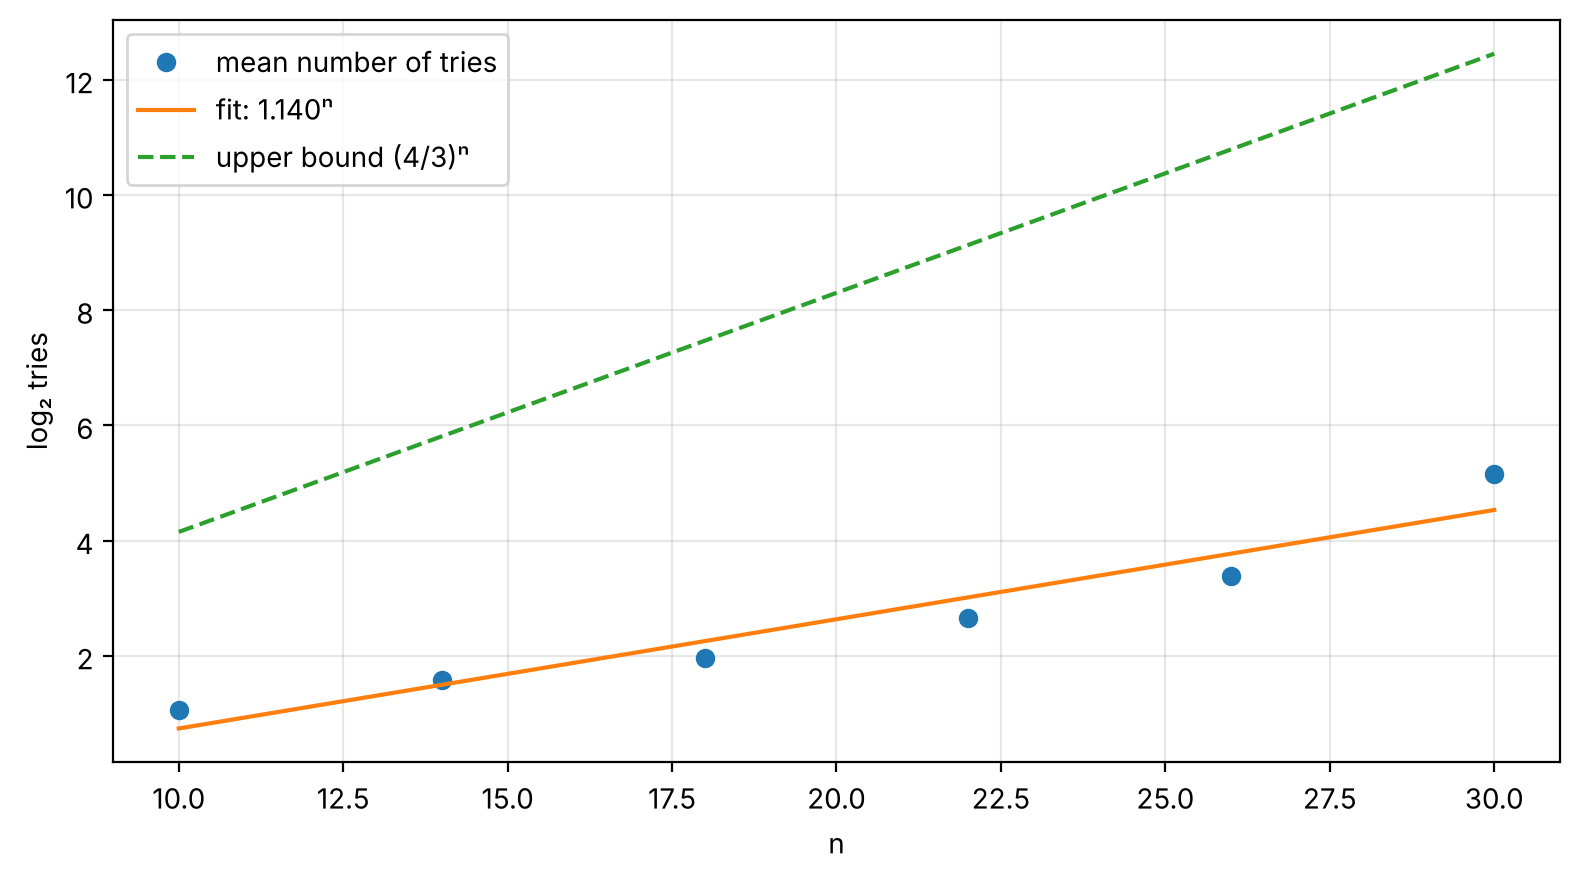

In [8]:
def sch_experiment(ns, per_n=12, alpha=4.2):
    med = []
    for n in ns:
        tries, s = [], 0
        while len(tries) < per_n:
            cnf = sat.random_ksat(n, int(alpha * n), 3, seed=50_000 + 1000 * n + s); s += 1
            if pycosat.solve([list(c) for c in cnf]) == 'UNSAT':
                continue
            x, st = sat.schoening(cnf, n, seed=s)
            assert x is not None and sat.satisfies(cnf, x)
            tries.append(st['tries'])
        med.append(np.mean(tries))
    return np.array(med)

ns_s = np.arange(10, 31, 4)
t0 = time.time(); tr = sch_experiment(ns_s); print(f'{time.time()-t0:.0f} s')
b, a = np.polyfit(ns_s, np.log2(tr), 1)
fig, ax = plt.subplots()
ax.plot(ns_s, np.log2(tr), 'o', label='mean number of tries')
ax.plot(ns_s, a + b * ns_s, '-', label=f'fit: {2**b:.3f}ⁿ')
ax.plot(ns_s, ns_s * math.log2(4 / 3), '--', label='upper bound (4/3)ⁿ')
ax.set_xlabel('n'); ax.set_ylabel('log₂ tries'); ax.legend()
fig.tight_layout(); fig.savefig(f'{FIG}/05_schoening.png', dpi=110); plt.show()

Random formulas need **far fewer** tries than $(4/3)^n$: they have many solutions,
whereas the bound is for the worst case with a single solution. The point of the analysis is the **guarantee**:
the success probability of a try is at least $(3/4)^n/\mathrm{poly}(n)$ for **any** satisfiable formula.

The chain of worst-case improvements for 3-SAT:

| Year | Algorithm | Time |
|---|---|---|
| — | brute force | $2^n$ |
| 1985 | Monien–Speckenmeyer | $1.619^n$ |
| 1999 | Schöning (randomized) | $1.334^n$ |
| 2005 | PPSZ (Paturi, Pudlák, Saks, Zane) | $1.308^n$ |
| 2011–2021 | Hertli; Hansen–Kaplan–Zamir–Zwick | $\approx1.307^n$ |

The base shrinks more and more slowly. ETH says it cannot be pushed down to 1.

## 6. Subset Sum: three levels of search

Given $a_0,\dots,a_{n-1}$ and $T$, find a mask $S$ with $\sum_{i\in S}a_i=T$.

### 6.1 Naive enumeration: $O(n\cdot2^n)$
For each of the $2^n$ masks, add up to $n$ numbers from scratch.

### 6.2 Gray code: $O(2^n)$
The reflected Gray code $g(i)=i\oplus(i\gg1)$ visits all masks so that consecutive masks differ in **one** bit.

**Which bit changes.** $g(i)\oplus g(i-1) = (i\oplus(i-1)) \oplus ((i\oplus(i-1))\gg1)$.
The number $i\oplus(i-1)$ has the form $0\dots01\dots1$ with $t+1$ ones, where $t=\mathrm{ctz}(i)$ (trailing zeros of $i$).
After XOR with its shift, a single one remains at position $t$. Hence:
$$\text{at step } i \text{ bit } \mathrm{ctz}(i) \text{ flips, and its new value is } g(i)_{\mathrm{ctz}(i)}.$$
If the bit became 1 the element joins the subset: $s \mathrel{+}= a_{\mathrm{ctz}(i)}$; if it became 0 it leaves: $s \mathrel{-}= a_{\mathrm{ctz}(i)}$.
One addition per mask. This is exactly what `ss_engine.v` does.

In [9]:
print(f"{'i':>2} {'bin(i)':>7} {'ctz':>4} {'g(i)':>6} {'dir':>4}  action")
for i in range(1, 16):
    t = (i & -i).bit_length() - 1
    g = i ^ (i >> 1)
    d = g >> t & 1
    print(f"{i:>2} {i:07b} {t:>4} {g:06b} {d:>4}  {'+' if d else '-'}a[{t}]")

 i  bin(i)  ctz   g(i)  dir  action
 1 0000001    0 000001    1  +a[0]
 2 0000010    1 000011    1  +a[1]
 3 0000011    0 000010    0  -a[0]
 4 0000100    2 000110    1  +a[2]
 5 0000101    0 000111    1  +a[0]
 6 0000110    1 000101    0  -a[1]
 7 0000111    0 000100    0  -a[0]
 8 0001000    3 001100    1  +a[3]
 9 0001001    0 001101    1  +a[0]
10 0001010    1 001111    1  +a[1]
11 0001011    0 001110    0  -a[0]
12 0001100    2 001010    0  -a[2]
13 0001101    0 001011    1  +a[0]
14 0001110    1 001001    0  -a[1]
15 0001111    0 001000    0  -a[0]


### 6.3 Meet-in-the-middle: $O(2^{n/2}\cdot n)$, base $\sqrt2\approx1.414$
Split the numbers into two halves $A$ and $B$ of size $n/2$. Every mask is a pair $(S_A,S_B)$, and
$$\sum S_A + \sum S_B = T \iff \sum S_B = T-\sum S_A.$$
1. List all $2^{n/2}$ sums of $B$ and sort them: $O(2^{n/2}\,n)$;
2. for each of the $2^{n/2}$ sums of $A$, binary-search for $T-s$: $O(2^{n/2}\,n)$.

Total $2^{n/2}=(\sqrt2)^n$ with $2^{n/2}$ memory (Horowitz–Sahni, 1974). Schroeppel–Shamir (1981) reduce memory
to $2^{n/4}$ at the same time. This is an **algorithmic** reduction of the base: the two halves are independent,
so instead of the product $2^{n/2}\cdot2^{n/2}$ the work becomes a sum: $2^{n/2}+2^{n/2}$.

### 6.4 Pseudo-polynomial DP: $O(nT)$
A bitset of reachable sums. Polynomial in the **value** $T$, but exponential in its **bit length** $\log T$.
No conflict with ETH: the problem is hard when the numbers have $\Theta(n)$ bits.

In [10]:
rows = []
for n in [12, 16, 20, 24]:
    a, T = ss.random_instance(n, bits=40, solvable=False, seed=n)   # no solution -> full sweep
    r = {'n': n}
    if n <= 20:
        t0 = time.time(); _, st = ss.naive(a, T); r['naive_adds'] = st['adds']; r['naive_s'] = time.time() - t0
    t0 = time.time(); _, st = ss.gray(a, T); r['gray_adds'] = st['adds']; r['gray_s'] = time.time() - t0
    t0 = time.time(); _, st = ss.meet_in_the_middle(a, T); r['mitm_sums'] = st['sums']; r['mitm_s'] = time.time() - t0
    rows.append(r)
print(f"{'n':>3} | {'naive, additions':>17} {'s':>6} | {'Gray':>10} {'s':>6} | {'MitM sums':>10} {'s':>6}")
for r in rows:
    nv = f"{r['naive_adds']:>17,} {r['naive_s']:6.2f}" if 'naive_adds' in r else f"{'—':>17} {'':>6}"
    print(f"{r['n']:>3} | {nv} | {r['gray_adds']:>10,} {r['gray_s']:6.2f} | {r['mitm_sums']:>10,} {r['mitm_s']:6.3f}")

# correctness on solvable instances
for seed in range(20):
    a, T = ss.random_instance(16, bits=30, seed=seed)
    for f in (ss.gray, ss.meet_in_the_middle):
        m, _ = f(a, T); assert m is not None and ss.mask_sum(a, m) == T
print('all solutions verified')

  n |  naive, additions      s |       Gray      s |  MitM sums      s
 12 |            24,576   0.00 |      4,095   0.00 |        128  0.000
 16 |           524,288   0.06 |     65,535   0.01 |        512  0.000
 20 |        10,485,760   1.29 |  1,048,575   0.16 |      2,048  0.001
 24 |                 —        | 16,777,215   2.71 |      8,192  0.007
all solutions verified


**Numbers:** the Gray code removes the factor $n$; at $n=24$ MitM enumerates 8,192 sums instead of 16.7 million.
Extrapolating to $n=60$ at $10^9$ ops/s: brute force $2^{60}$ takes 36 years; MitM $2\cdot2^{30}\cdot60$ takes a couple
of minutes, but the table of $2^{30}$ sums needs 8–16 GB. Schroeppel–Shamir keeps about $2^{15}$ entries at the same time.

## 7. FPGA #1: parallel 3-SAT brute force (`rtl/sat_brute.v`)

### 7.1 How a clause becomes logic
A clause is stored as two masks: `pos` (literals $x_i$) and `neg` (literals $\neg x_i$). Assignment $a$ satisfies it iff
$$\bigl((a\,\&\,\mathrm{pos}) \mid (\sim a\,\&\,\mathrm{neg})\bigr)\neq0.$$
The masks are constants (from `$readmemh`), so synthesis folds each clause into a function of **three**
assignment bits, i.e. one LUT6, and the whole formula into an AND tree. Checking **all** $m$ clauses takes one clock.

### 7.2 Parallelism
$P=2^{\text{LOGP}}$ identical cores. Core $k$ checks the assignment $a=\{\text{cnt},k\}$: the low LOGP bits are
hard-wired into the core as constants, the high bits come from a shared counter. The constants simplify clauses on
the low variables (a literal is either immediately true — the clause disappears — or drops out of the clause),
so the cores get even smaller.

```
cnt ──► [P copies of the formula] ──► ok[P-1:0] ──► [priority encoder] ──► solution = cnt·P + k
```
A full sweep takes $2^n/P$ cycles. Assignments are visited in increasing order, so the one found is the **minimal**
satisfying assignment and can be compared with `sat.brute_force`.

In [11]:
# RTL comments are in Russian; code only is shown here (the logic is explained above)
src = [l for l in open('../rtl/sat_brute.v') if not l.lstrip().startswith('//')]
print(''.join(src)[:2200])

module sat_brute #(
    parameter N     = 16,
    parameter M     = 68,
    parameter LOGP  = 2,
    parameter PFILE = "pos.mem",
    parameter NFILE = "neg.mem"
) (
    input  wire          clk,
    input  wire          rst,
    input  wire          start,
    output reg           done,
    output reg           sat,
    output reg  [N-1:0]  solution,
    output reg  [47:0]   cycles
);
    localparam P  = 1 << LOGP;
    localparam CW = N - LOGP;

    reg [N-1:0] pos [0:M-1];
    reg [N-1:0] neg [0:M-1];
    initial begin
        $readmemh(PFILE, pos);
        $readmemh(NFILE, neg);
    end

    reg  [CW-1:0] cnt;
    reg           busy;
    wire [P-1:0]  ok;

    genvar k;
    generate
        for (k = 0; k < P; k = k + 1) begin : core
            wire [N-1:0] a;
            if (LOGP == 0) begin : g0
                assign a = cnt;
            end else begin : g1
                assign a = {cnt, k[LOGP-1:0]};
            end
            reg r;
            integer c;
            always 

In [12]:
# Icarus Verilog run: compare with Python and watch the cycle count
n = 14
s = 0
while True:                       # take a satisfiable formula near the threshold
    cnf_sat = sat.random_3sat_ratio(n, 4.0, seed=300 + s); s += 1
    x_ref, st = sat.brute_force(cnf_sat, n)
    if x_ref is not None and st['checked'] > 2000:
        break
ref_int = sum(b << i for i, b in enumerate(x_ref)) if x_ref else None
print('Python: minimal solution', ref_int, 'checked', st['checked'])
for logp in range(0, 5):
    r = fpga.sim_sat(cnf_sat, n, logp)
    ok = r['sat'] and r['x'] == ref_int
    print(f"LOGP={logp} P={2**logp:2d}: solution={r['x']:6d} cycles={r['cycles']:6d}  "
          f"expected ≈ {math.ceil(st['checked'] / 2**logp):6d}  {'OK' if ok else 'FAIL'}")

Python: minimal solution 11605 checked 11606


LOGP=0 P= 1: solution= 11605 cycles= 11606  expected ≈  11606  OK


LOGP=1 P= 2: solution= 11605 cycles=  5803  expected ≈   5803  OK


LOGP=2 P= 4: solution= 11605 cycles=  2902  expected ≈   2902  OK


LOGP=3 P= 8: solution= 11605 cycles=  1451  expected ≈   1451  OK


LOGP=4 P=16: solution= 11605 cycles=   726  expected ≈    726  OK


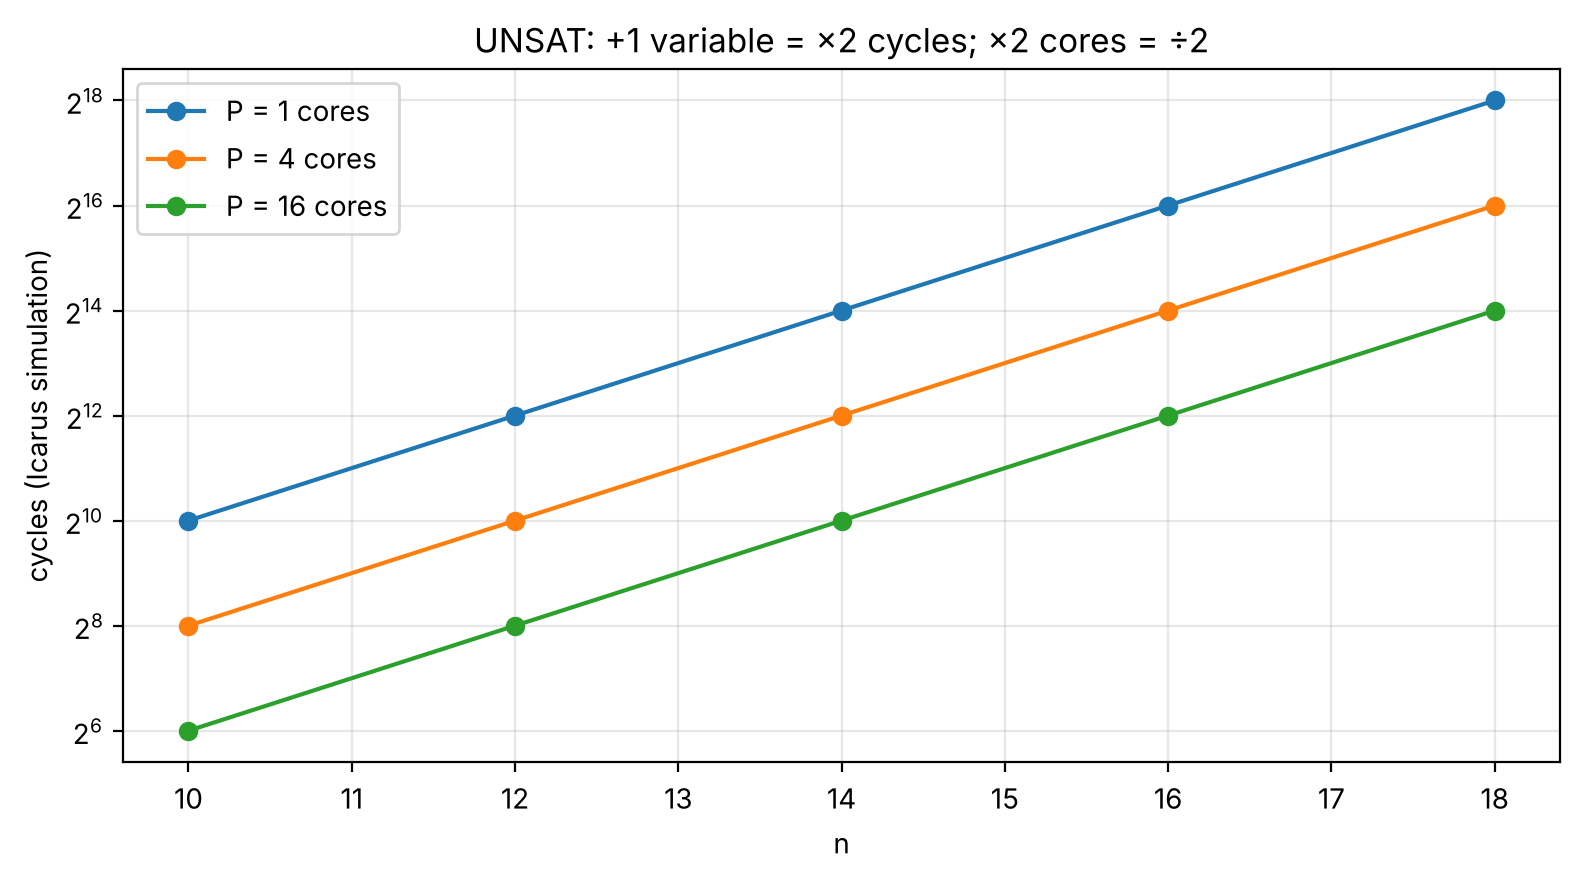

P= 1: [1024, 4096, 16384, 65536, 262144]  2^(n-LOGP) = [1024, 4096, 16384, 65536, 262144]
P= 4: [256, 1024, 4096, 16384, 65536]  2^(n-LOGP) = [256, 1024, 4096, 16384, 65536]
P=16: [64, 256, 1024, 4096, 16384]  2^(n-LOGP) = [64, 256, 1024, 4096, 16384]


In [13]:
# Unsatisfiable formulas: a clean 2^(n-LOGP) exponential
unsat_cnfs = {}
for n in range(10, 19, 2):
    s = 0
    while True:
        cnf = sat.random_3sat_ratio(n, 6.0, seed=900 + 37 * n + s); s += 1
        if pycosat.solve([list(c) for c in cnf]) == 'UNSAT':
            unsat_cnfs[n] = cnf; break
cyc = {}
for logp in [0, 2, 4]:
    cyc[logp] = [fpga.sim_sat(unsat_cnfs[n], n, logp)['cycles'] for n in unsat_cnfs]
ns_u = list(unsat_cnfs)
fig, ax = plt.subplots()
for logp, c in cyc.items():
    ax.semilogy(ns_u, c, 'o-', base=2, label=f'P = {2**logp} cores')
ax.set_xlabel('n'); ax.set_ylabel('cycles (Icarus simulation)'); ax.legend()
ax.set_title('UNSAT: +1 variable = ×2 cycles; ×2 cores = ÷2')
fig.tight_layout(); fig.savefig(f'{FIG}/07_sat_cycles.png', dpi=110); plt.show()
for logp, c in cyc.items():
    print(f'P={2**logp:2d}:', c, ' 2^(n-LOGP) =', [2**(n - logp) for n in ns_u])

### 7.3 How many cores fit into an XC7Z010 and what that buys
A core for $m$ clauses is ≈ $m$ LUTs (clauses) + $m/5$ (AND tree). For $n=40$, $m=171$ that is ~205 LUTs,
i.e. about 68 cores at 80% of 17,600 LUTs. The counter fans out to every core, so a realistic clock is 50–100 MHz.

In [14]:
for n in [32, 40, 48, 60]:
    m = round(4.27 * n)
    core = fpga.sat_core_cost(m)
    P = 2 ** int(math.log2(core.fit()))
    for f in [50e6, 100e6]:
        rate = P * f
        print(f"n={n} m={m}: core ~{core.lut} LUT, P={P}, {f/1e6:.0f} MHz -> {rate:.1e} assign/s; "
              f"full sweep {T_(2**n / rate)}; CPU (1e8/s) {T_(2**n / 1e8)}; "
              f"gain +{fpga.extra_vars(rate / 1e8):.1f} vars")

n=32 m=137: core ~165 LUT, P=64, 50 MHz -> 3.2e+09 assign/s; full sweep 1.3 s; CPU (1e8/s) 42.9 s; gain +5.0 vars
n=32 m=137: core ~165 LUT, P=64, 100 MHz -> 6.4e+09 assign/s; full sweep 671.1 ms; CPU (1e8/s) 42.9 s; gain +6.0 vars
n=40 m=171: core ~206 LUT, P=64, 50 MHz -> 3.2e+09 assign/s; full sweep 5.7 min; CPU (1e8/s) 3.1 h; gain +5.0 vars
n=40 m=171: core ~206 LUT, P=64, 100 MHz -> 6.4e+09 assign/s; full sweep 2.9 min; CPU (1e8/s) 3.1 h; gain +6.0 vars
n=48 m=205: core ~246 LUT, P=32, 50 MHz -> 1.6e+09 assign/s; full sweep 2.0 days; CPU (1e8/s) 32.6 days; gain +4.0 vars
n=48 m=205: core ~246 LUT, P=32, 100 MHz -> 3.2e+09 assign/s; full sweep 1.0 days; CPU (1e8/s) 32.6 days; gain +5.0 vars
n=60 m=256: core ~308 LUT, P=32, 50 MHz -> 1.6e+09 assign/s; full sweep 22.8 years; CPU (1e8/s) 365 years; gain +4.0 vars
n=60 m=256: core ~308 LUT, P=32, 100 MHz -> 3.2e+09 assign/s; full sweep 11.4 years; CPU (1e8/s) 365 years; gain +5.0 vars


## 8. FPGA #2: Gray-code Subset Sum engine (`rtl/ss_engine.v`, `rtl/ss_array.v`)

### 8.1 One engine — one subset per clock
Register `sum` holds the sum for mask $g(\text{cnt})$. Each clock, in parallel:
- the comparator `sum == T`;
- the next sum `sum + delta`, where `delta` is the increment for bit $\mathrm{ctz}(\text{cnt}+1)$.

### 8.2 The sketch's mistake and the right way to pick the increment
The first sketch used `sum + (gray_next[bit] ? a[bit] : -a[bit])`. That is an $N{:}1$ multiplexer of width $W$:
about 10 LUTs per bit at $N=32$, i.e. ~400 LUTs just for the selection, so 64 engines do not fit.

The fix: precompute a table of $2N$ words
$$\mathrm{dtab}[\{\mathrm{idx},\mathrm{dir}\}] = \begin{cases}+a_{\mathrm{idx}}, & \mathrm{dir}=1\\ -a_{\mathrm{idx}}, & \mathrm{dir}=0\end{cases}$$
and place it in distributed RAM. `RAM64X1` stores 64 one-bit words in **one** LUT6, so a table of up to 64 words
costs $W$ LUTs. The sign selection disappears as well.

### 8.3 Splitting work between engines
Mask $=\{k,\text{low}\}$: the top $K$ elements are fixed for engine $k$ (their sum is the constant `base[k]`),
and each engine enumerates the low $N_L=N-K$ itself. $P=2^K$ engines cover everything in $2^{N-K}$ cycles.

In [15]:
src = [l.split('//')[0].rstrip() + '\n' if '//' in l else l
       for l in open('../rtl/ss_engine.v') if not l.lstrip().startswith('//')]
print(''.join(src))

module ss_engine #(
    parameter NL    = 10,
    parameter W     = 40,
    parameter DFILE = "dtab.mem"
) (
    input  wire                 clk,
    input  wire                 rst,
    input  wire                 start,
    input  wire signed [W-1:0]  base,
    input  wire signed [W-1:0]  T,
    output reg                  busy,
    output reg                  done,
    output reg                  found,
    output reg  [NL-1:0]        fmask
);
    localparam IW = (NL <= 1) ? 1 : $clog2(NL);

    (* ram_style = "distributed" *)
    reg signed [W-1:0] dtab [0:2*NL-1];
    initial $readmemh(DFILE, dtab);

    reg  [NL-1:0] cnt;
    wire [NL-1:0] nxt  = cnt + 1'b1;
    wire [NL-1:0] gcur = cnt ^ (cnt >> 1);
    wire [NL-1:0] gnxt = nxt ^ (nxt >> 1);

    reg [IW-1:0] idx;
    integer j;
    always @* begin
        idx = {IW{1'b0}};
        for (j = NL - 1; j >= 0; j = j - 1)
            if (nxt[j]) idx = j[IW-1:0];
    end

    wire               dir   = gnxt[idx];
    wire signed [W-1:

In [16]:
# Compare with Python on solvable and unsolvable instances
for (n, K, solv, seed) in [(14, 0, True, 1), (14, 2, True, 2), (16, 3, True, 3), (16, 4, True, 4),
                           (14, 2, False, 5), (16, 3, False, 6)]:
    a, T = ss.random_instance(n, bits=30, solvable=solv, seed=seed)
    r = fpga.sim_subset_sum(a, T, K)
    ok = (r['found'] and ss.mask_sum(a, r['mask']) == T) or (not solv and not r['found'])
    print(f"n={n} K={K} P={2**K:2d} {'SAT  ' if solv else 'UNSAT'} -> found={int(r['found'])} "
          f"mask={r['mask']:#07x} cycles={r['cycles']:6d} (full sweep {2**(n-K)})  {'OK' if ok else 'FAIL'}")

n=14 K=0 P= 1 SAT   -> found=1 mask=0x0327b cycles=  9135 (full sweep 16384)  OK
n=14 K=2 P= 4 SAT   -> found=1 mask=0x013b9 cycles=   723 (full sweep 4096)  OK


n=16 K=3 P= 8 SAT   -> found=1 mask=0x04266 cycles=   957 (full sweep 8192)  OK


n=16 K=4 P=16 SAT   -> found=1 mask=0x0c3e2 cycles=   702 (full sweep 4096)  OK


n=14 K=2 P= 4 UNSAT -> found=0 mask=0x00000 cycles=  4097 (full sweep 4096)  OK


n=16 K=3 P= 8 UNSAT -> found=0 mask=0x00000 cycles=  8193 (full sweep 8192)  OK


In [17]:
# Resources: multiplexer vs LUTRAM, how many engines fit, and the resulting speed
print(f"{'variant':22} {'N_L':>4} {'W':>3} {'LUT/engine':>11} {'engines':>8}")
for NL in [16, 26, 32]:
    for lutram in (False, True):
        c = fpga.ss_engine_cost(NL, 40, lutram)
        print(f"{c.name:22} {NL:>4} {40:>3} {c.lut:>11} {c.fit():>8}")
print()
for n in [40, 50, 60]:
    c = fpga.ss_engine_cost(n - 6, 48, True)
    P = 2 ** int(math.log2(c.fit()))
    for f in [100e6, 200e6]:
        rate = P * f
        print(f"n={n}: P={P}, {f/1e6:.0f} MHz -> {rate:.2e} masks/s, sweep {T_(2**n/rate)}; "
              f"CPU Gray (1e9/s) {T_(2**n/1e9)}; MitM on CPU ~{T_(2*2**(n/2)*n/1e9)}")

variant                 N_L   W  LUT/engine  engines
ss_engine (mux)          16  40         278       50
ss_engine (LUTRAM)       16  40         118      119
ss_engine (mux)          26  40         533       26
ss_engine (LUTRAM)       26  40         133      105
ss_engine (mux)          32  40         542       25
ss_engine (LUTRAM)       32  40         142       99

n=40: P=64, 100 MHz -> 6.40e+09 masks/s, sweep 2.9 min; CPU Gray (1e9/s) 18.3 min; MitM on CPU ~83.9 ms
n=40: P=64, 200 MHz -> 1.28e+10 masks/s, sweep 1.4 min; CPU Gray (1e9/s) 18.3 min; MitM on CPU ~83.9 ms
n=50: P=32, 100 MHz -> 3.20e+09 masks/s, sweep 4.1 days; CPU Gray (1e9/s) 13.0 days; MitM on CPU ~3.4 s
n=50: P=32, 200 MHz -> 6.40e+09 masks/s, sweep 2.0 days; CPU Gray (1e9/s) 13.0 days; MitM on CPU ~3.4 s
n=60: P=32, 100 MHz -> 3.20e+09 masks/s, sweep 11.4 years; CPU Gray (1e9/s) 36.5 years; MitM on CPU ~2.1 min
n=60: P=32, 200 MHz -> 6.40e+09 masks/s, sweep 5.71 years; CPU Gray (1e9/s) 36.5 years; MitM on CPU ~2.

**Section summary.** At $n=40$, 64 engines fit; at 200 MHz that is $1.3\cdot10^{10}$ masks/s, about ×13 over one
CPU core, i.e. **+3.7 variables**. For $n\ge50$ the increment table no longer fits into a single RAM64X1 and only
32 engines fit. Meet-in-the-middle on the same CPU doubles $n$: at $n=60$ the FPGA sweep takes almost 6 years,
MitM a couple of minutes.

The FPGA helps MitM too, but differently: the PL generates the half-sums in Gray order (each engine is a stream of
sums) while the ARM sorts and merges them. The limit is memory: $2^{n/2}$ entries do not fit into 2.1 Mbit of BRAM,
so you need DDR or the Schroeppel–Shamir variant with $2^{n/4}$ memory.

> The resource numbers here come from a model. Exact figures come from `utilization.rpt` after Vivado synthesis.
> The engine's critical path is `cnt → +1 → ctz → LUTRAM → 40-bit adder`. For 200 MHz it is pipelined:
> idx and delta are computed one clock earlier (they depend only on cnt).

## 9. FPGA #3, the right way: DPLL on the ARM + single-cycle BCP (`rtl/bcp_unit.v`)

Sections 7–8 showed that parallel brute force only buys a **constant**. The right combination is to lower the base
algorithmically first (DPLL/CDCL) and then accelerate its most frequent step.

**BCP (Boolean Constraint Propagation)** is a pass over all clauses under a partial assignment: find a conflict
(all literals of a clause are false) or a unit clause (no true literal and exactly one free literal).
CDCL solvers spend 80–90% of their time here.

On an FPGA each clause is a separate small circuit fed by the `assigned`/`value` bits of its three variables:
$$\text{T}=\text{asg}\wedge(\text{val}\oplus s),\quad \text{F}=\text{asg}\wedge\neg(\text{val}\oplus s),\quad \text{U}=\neg\text{asg}$$
$$\text{sat}=\bigvee \text{T},\quad \text{conflict}=\bigwedge \text{F},\quad \text{unit}=\neg\text{sat}\wedge(\#\text{U}=1).$$
All $m$ clauses are evaluated **simultaneously**, in one clock, instead of $m$ CPU steps.

### 9.1 Check: a real DPLL trace against the Verilog
Run `sat.dpll`, recording every partial assignment on which it scanned the clauses, feed the same assignments
into `bcp_unit.v`, and compare the answers.

In [18]:
n = 16
cnf = sat.random_3sat_ratio(n, 4.27, seed=7)
trace = []
x, st = sat.dpll(cnf, n, trace=trace)
print('DPLL:', 'SAT' if x else 'UNSAT', st, 'states recorded:', len(trace))
hw = fpga.sim_bcp(cnf, n, trace)
mism = 0
for (asg, val), h in zip(trace, hw):
    ref = fpga.bcp_reference(cnf, n, asg, val)
    same = h[:3] == ref[:3] and (not ref[2] or h[3:] == ref[3:])
    mism += not same
from collections import Counter
print('mismatches vs Python:', mism, 'of', len(hw))
print('outcomes (conflict, all_sat, unit):', Counter(h[:3] for h in hw))

DPLL: SAT {'nodes': 13, 'bcp_rounds': 36, 'clause_checks': 2448} states recorded: 36
mismatches vs Python: 0 of 36
outcomes (conflict, all_sat, unit): Counter({(0, 0, 1): 23, (0, 0, 0): 10, (1, 0, 0): 2, (0, 1, 0): 1})


### 9.2 What it buys
DPLL time model: $\;t = R\cdot t_{\text{BCP}} + \text{everything else}$, where $R$ is the number of BCP passes.

- CPU: $t_{\text{BCP}}\approx m\cdot 5$ ns (a pass over $m$ clauses with memory indirection).
- FPGA: $t_{\text{BCP}} = 1$ clock, but if the ARM pokes the PL for every pass over AXI-GP, each pass adds
  ~0.3–1 µs of bus latency. That is why in practice the whole propagation loop moves into the PL
  (assign the unit literal → BCP again → …), and the ARM only gets the result: a conflict or a new branching point.

In [19]:
ns_b = [40, 60, 80]
print(f"{'n':>3} {'nodes':>7} {'BCP passes':>11} | {'CPU BCP':>10} {'PL+AXI per pass':>16} {'PL whole loop':>14}")
for n in ns_b:
    m = round(4.27 * n)
    R, N_ = [], []
    for s in range(7):
        _, st = sat.dpll(sat.random_3sat_ratio(n, 4.27, seed=31 * n + s), n)
        R.append(st['bcp_rounds']); N_.append(st['nodes'])
    R, N_ = np.median(R), np.median(N_)
    cpu = R * m * 5e-9
    pl_axi = R * (1 / 100e6 + 0.5e-6)
    pl_loop = R / 100e6 + N_ * 0.5e-6        # one AXI transaction per tree node
    print(f"{n:>3} {N_:>7.0f} {R:>11.0f} | {T_(cpu):>10} {T_(pl_axi):>16} {T_(pl_loop):>14}")

  n   nodes  BCP passes |    CPU BCP  PL+AXI per pass  PL whole loop


 40     147         898 |   767.8 µs         458.0 µs        82.5 µs


 60     439        3723 |     4.8 ms           1.9 ms       256.7 µs


 80     692        6467 |    11.1 ms           3.3 ms       410.7 µs


**Conclusion.** Accelerating BCP is the same kind of constant as in sections 7–8, but applied on top of an algorithm
with a base of about 1.1 instead of 2. The constant multiplies an exponent that has already been reduced.
Order matters: **first the base, then the constant.**

## 10. The big picture
Time to solution for different strategies. The DPLL base was measured in section 4 on **random** formulas
(not the worst case); the PPSZ line is a guaranteed bound for **any** formula. Speeds come from sections 7–9.

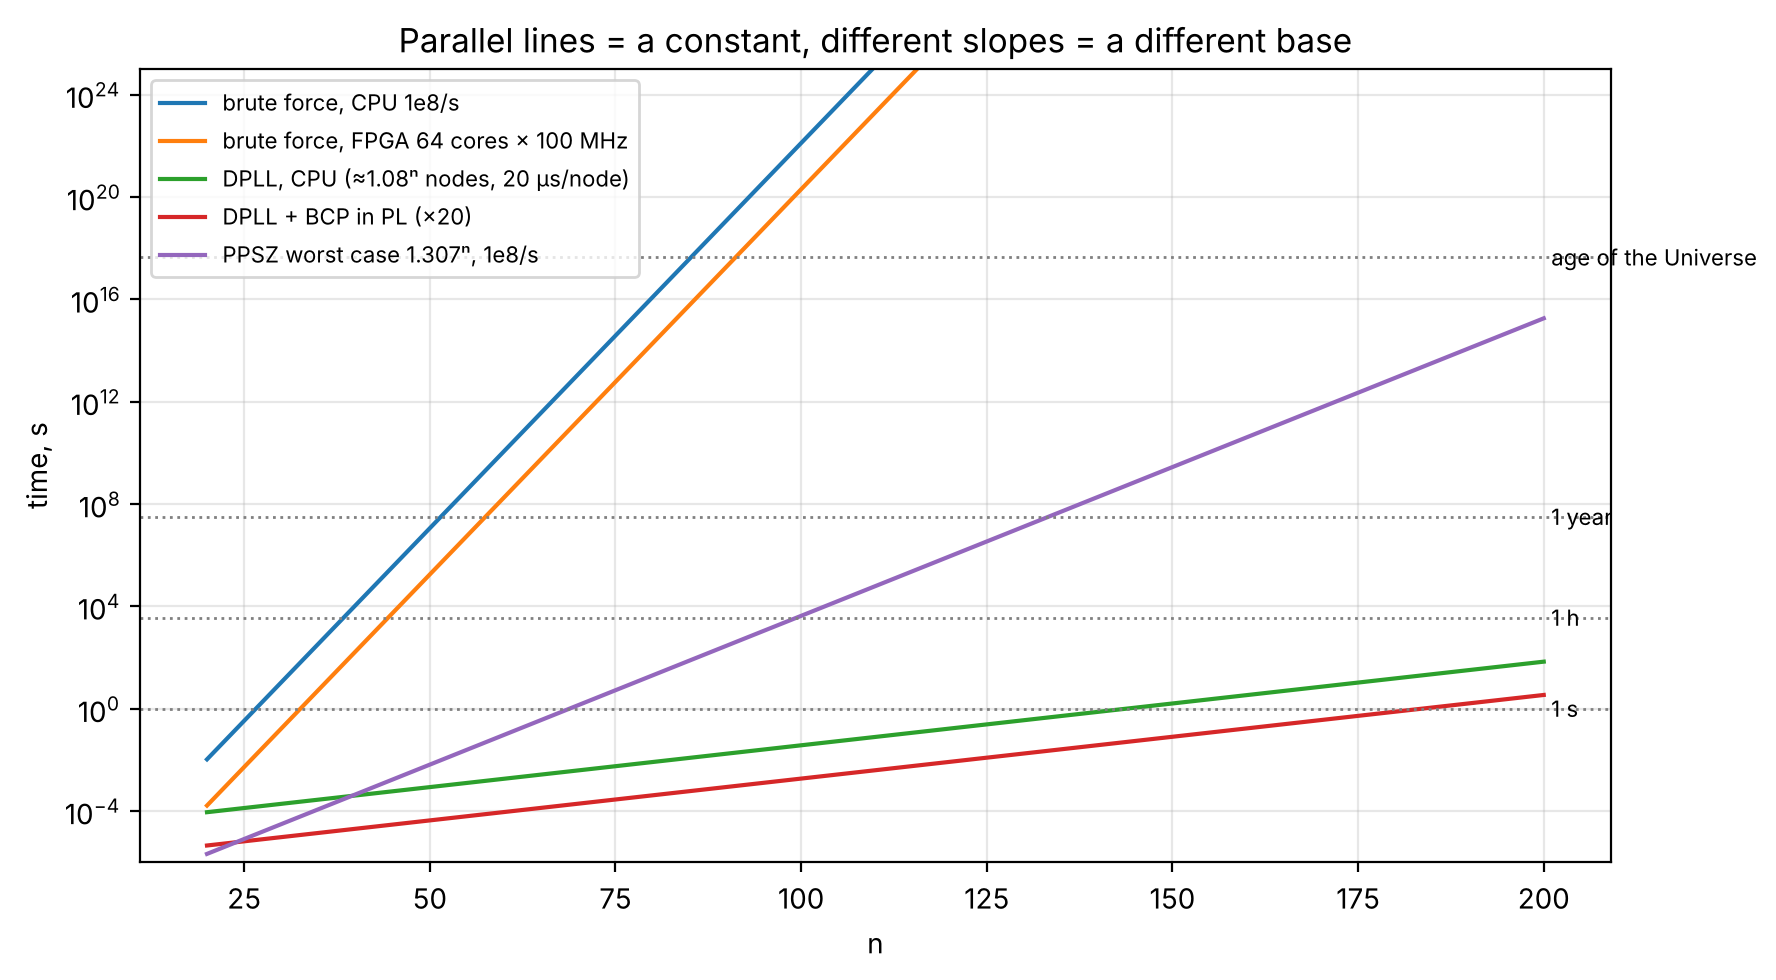

In [20]:
ns_all = np.arange(20, 201)
c_dp = fits['DPLL']
lines = {
    'brute force, CPU 1e8/s':               2.0 ** ns_all / 1e8,
    'brute force, FPGA 64 cores × 100 MHz': 2.0 ** ns_all / 6.4e9,
    f'DPLL, CPU (≈{c_dp:.2f}ⁿ nodes, 20 µs/node)': c_dp ** ns_all * 20e-6,
    'DPLL + BCP in PL (×20)':               c_dp ** ns_all * 1e-6,
    'PPSZ worst case 1.307ⁿ, 1e8/s':        1.307 ** ns_all / 1e8,
}
fig, ax = plt.subplots(figsize=(9, 5))
for k, v in lines.items():
    ax.semilogy(ns_all, v, label=k)
for y, lab in [(1, '1 s'), (3600, '1 h'), (3.156e7, '1 year'), (4.35e17, 'age of the Universe')]:
    ax.axhline(y, color='gray', ls=':', lw=1); ax.text(201, y, lab, fontsize=8, va='center')
ax.set_ylim(1e-6, 1e25); ax.set_xlabel('n'); ax.set_ylabel('time, s'); ax.legend(fontsize=8)
ax.set_title('Parallel lines = a constant, different slopes = a different base')
fig.tight_layout(); fig.savefig(f'{FIG}/10_summary.png', dpi=110); plt.show()

### 10.1 Where the limit is
- **The base can be lowered:** $2\to1.839\to1.619\to1.334\to1.307$ (worst-case 3-SAT).
- **ETH:** you cannot get to $2^{o(n)}$; there is an $s_3>0$ with time at least $2^{s_3 n}$.
- **SETH:** for wide clauses the base tends to 2 and brute force is almost optimal. Consequences:
  no $O(N^{2-\varepsilon})$ for edit distance, LCS, Orthogonal Vectors.
- **Hardware** changes neither $s_3$ nor the base: $P$ cores are worth $\log_2 P$ variables.

### 10.2 A recipe for your own problem
1. Write down the recurrence of your current search and find $c$ from $(*)$.
2. Look for branching where every branch fixes more variables.
3. Repeated subproblems → memoization / DP over subsets ($n!\to n^2 2^n$).
4. The problem splits into independent halves → meet-in-the-middle ($c\to\sqrt c$).
5. There is a small parameter $k$ → FPT ($c^n\to c^k\,\mathrm{poly}(n)$).
6. Consider randomization (Schöning).
7. **Only then** move the most frequent uniform operation to the FPGA: BCP, sum generation, clause checking.

## 11. Exercises

1. **Recurrence.** Branching on a vertex of degree $\ge3$ for Independent Set gives the vector $(1,4)$.
   Compute $c$ with `rc.branching_number` and derive it by hand from the characteristic polynomial $c^4-c^3-1=0$.
2. **k-SAT.** Plot $c(k)$ for clause branching $(1,\dots,k)$ and for Schöning $2(1-1/k)$ for $k=3..10$.
   How fast do both tend to 2? Relate this to SETH.
3. **Hard formulas for DPLL.** Generate pigeonhole formulas (PHPₙ: $n+1$ pigeons, $n$ holes)
   and measure the DPLL base. Compare with random formulas.
4. **FPGA.** In `ss_engine.v`, move `idx`, `dir` and `delta` into a pipeline register (they depend only on `cnt`)
   and check in Icarus that the answers do not change. How much shorter is the logic path per clock?
5. **MitM on Zynq.** Estimate at which $n$ a table of $2^{n/2}$ sums of 6 bytes each stops fitting into 2.1 Mbit
   of BRAM and into 512 MB of DDR. What does the Schroeppel–Shamir variant change?
6. **BCP in hardware.** Extend `bcp_unit.v` so that it assigns the unit literal itself and repeats the pass
   until a conflict or a fixed point. How many clocks does such a loop take on average on the trace from section 9?